In [1]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="gpt-oss:120b-cloud")
print('Model is ready to use!')

c:\Users\ak60492\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model is ready to use!


In [18]:
from dotenv import load_dotenv, find_dotenv
import os

env_path = find_dotenv()
load_dotenv(env_path)
tavilyApiKey = os.getenv('TAVILY_API_KEY')

In [19]:
# Tools definition
from langchain_community.tools import tool
from langchain_community.tools import DuckDuckGoSearchResults, WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
from tavily import TavilyClient

@tool
def get_news(query: str) -> str:
    """Helps to get news details for a specific subject"""
    duckDuckGoTool = DuckDuckGoSearchResults()
    return duckDuckGoTool.invoke(query)

@tool
def get_blog(subject: str) -> str:
    """Gets the detailed blog on the subject using wikipedia"""
    wikipediaWrapper = WikipediaAPIWrapper(top_k_results=2, doc_content_chars_max=500)
    wikipediaTool = WikipediaQueryRun(api_wrapper=wikipediaWrapper)
    result = wikipediaTool.run({"query": subject})
    print(f'Wikipedia result {result}')
    return f'Wikipedia result {result}'

@tool
def web_search(search_query: str) -> str:
    """Web search tool that searches web pages over internet for the given search query"""
    tavily_client = TavilyClient(api_key=tavilyApiKey)
    response = tavily_client.search(search_query)
    return response


AI Agent is created successfully..


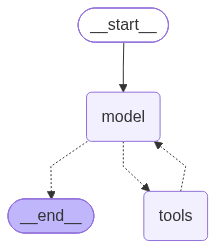

In [20]:
from langchain.agents import create_agent

agent = create_agent(
    model=model,
    tools=[get_news, get_blog, web_search],
    system_prompt="You are a helpful assistant. Please suggest the tool get_weather if someone asks for weather infprmation. Please suggest get_stock_price tool if someone asks about stock price of a given stock."
)
print("AI Agent is created successfully..")
agent

In [4]:
response = agent.invoke({
    "messages": [
        {"role": "user", "content": "What are the headlines on the subject middle east war?"}
    ]
})
response

{'messages': [HumanMessage(content='What are the headlines on the subject middle east war?', additional_kwargs={}, response_metadata={}, id='dfba44e3-9ea7-41d8-ae1b-12d01616742a'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-30T08:54:50.24339809Z', 'done': True, 'done_reason': 'stop', 'total_duration': 341738950, 'load_duration': None, 'prompt_eval_count': 178, 'prompt_eval_duration': None, 'eval_count': 72, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a18c04-da18-74e0-a6dd-34488eb3694d-0', tool_calls=[{'name': 'get_news', 'args': {'query': 'middle east war'}, 'id': '9ca310ff-37ea-425c-bfc7-77e6b3eabcff', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 178, 'output_tokens': 72, 'total_tokens': 250}),
  ToolMessage(content='snippet: Since 28 February 2026, the United States and Israel have been at war with Iran and its re

In [ ]:
response = agent.invoke({
    "messages": [
        {"role": "user", "content": "Global Warming"}
    ]
})
response

In [22]:
response = agent.invoke({
    "messages": [
        {"role": "user", "content": "Search for best restaurants in Pune"}
    ]
})
response

{'messages': [HumanMessage(content='Search for best restaurants in Pune', additional_kwargs={}, response_metadata={}, id='f38ee847-bf4d-492d-891b-76d19ad20c95'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-30T09:22:27.997041073Z', 'done': True, 'done_reason': 'stop', 'total_duration': 347264360, 'load_duration': None, 'prompt_eval_count': 231, 'prompt_eval_duration': None, 'eval_count': 48, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a18c1e-265d-74a2-b4b9-489ca07357fe-0', tool_calls=[{'name': 'web_search', 'args': {'search_query': 'best restaurants in Pune'}, 'id': 'cf8fbd19-2f9d-4f29-b285-b7b2cfa6b2d5', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 231, 'output_tokens': 48, 'total_tokens': 279}),
  ToolMessage(content='{"query": "best restaurants in Pune", "follow_up_questions": null, "answer": null, "images": [], "r